# Computer Vision Homework 1 – Part 3 (Detailed)
**Student:** Rouja Aghajani - 810101380  
**Date:** 2026-05-10  

This notebook processes a video file:  
1. Load Original_Vid.mp4 and extract properties (frame count, FPS).  
2. Add **Salt & Pepper** noise to every frame.  
3. Apply a **median filter** (non‑convolutional low‑pass) to remove the noise.  
4. Save the noisy and filtered videos as separate MP4 files.  


## 1. Load Video and Get Properties
We use OpenCV's VideoCapture to read the video.  
Properties obtained:
- **Frame count** – total number of frames  
- **FPS** – frames per second (affects playback speed)  
- **Resolution** – width × height (must remain same for output videos)  


In [1]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt

output_folder = "Part3_Results"
os.makedirs(output_folder, exist_ok=True)

video_path = 'Original_Vid.mp4'
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise FileNotFoundError(f"Could not open {video_path}")

frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print(f"Total frames: {frame_count}")
print(f"FPS: {fps}")
print(f"Resolution: {width} x {height}")
cap.release()


Total frames: 309
FPS: 29.97
Resolution: 640 x 480


## 2. Adding Salt & Pepper Noise to Video
**Salt‑and‑pepper noise** randomly sets some pixels to white (255) or black (0).  
We apply it to each frame **independently** so the noise changes over time.

### Why convert to grayscale?
- The median filter we will use works on single‑channel images.  
- Salt & pepper noise is intensity‑based, so grayscale is sufficient.  
- We will convert the final filtered frames back to BGR for video saving.  

The function below adds noise to a grayscale frame:
- amount = percentage of corrupted pixels (e.g., 0.05 = 5%).
- Half of them become salt (white), half pepper (black).


In [2]:
def add_salt_pepper_noise(gray_frame, amount=0.05):
    noisy = gray_frame.copy()
    h, w = gray_frame.shape
    total_pixels = h * w
    num_salt = int(amount * total_pixels * 0.5)
    num_pepper = int(amount * total_pixels * 0.5)
    
    # Salt (white)
    salt_rows = np.random.randint(0, h, num_salt)
    salt_cols = np.random.randint(0, w, num_salt)
    noisy[salt_rows, salt_cols] = 255
    
    # Pepper (black)
    pepper_rows = np.random.randint(0, h, num_pepper)
    pepper_cols = np.random.randint(0, w, num_pepper)
    noisy[pepper_rows, pepper_cols] = 0
    
    return noisy


## 3. Removing Noise with Median Filter
Median filter is a non‑convolutional low‑pass filter.  
For each pixel, it takes the median value of its neighbourhood (e.g., 3×3).  

Why median?  
- Salt & pepper noise produces extreme outliers (0 or 255).  
- Median filter removes outliers without blurring edges as much as a mean filter.  
- It is non‑convolutional because it does not use a kernel in the linear algebra sense; it sorts pixel values and picks the middle.

We use OpenCV's cv2.medianBlur (kernel size = 3).


In [3]:
def apply_median_filter(gray_frame, kernel_size=3):
    return cv2.medianBlur(gray_frame, kernel_size)


## 4. Visual Check on First Frame
To verify the process, we extract the first frame, apply noise, then filter, and display all three side‑by‑side.


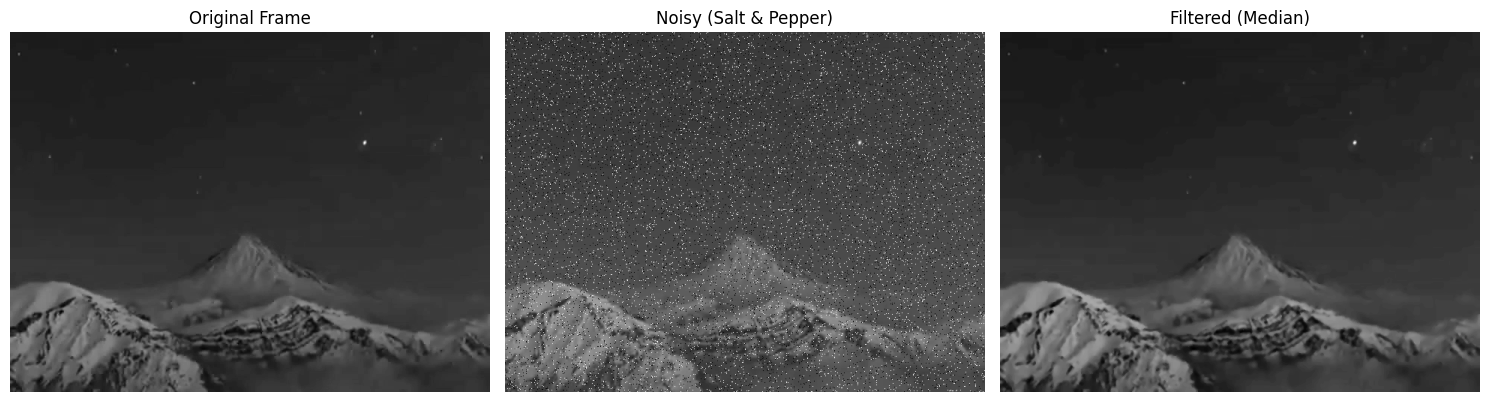

In [4]:
cap = cv2.VideoCapture(video_path)
ret, first_frame_bgr = cap.read()
cap.release()
if ret:
    first_frame_gray = cv2.cvtColor(first_frame_bgr, cv2.COLOR_BGR2GRAY)
    noisy_gray = add_salt_pepper_noise(first_frame_gray, amount=0.05)
    filtered_gray = apply_median_filter(noisy_gray, kernel_size=3)
    
    plt.figure(figsize=(15,5))
    plt.subplot(1,3,1); plt.imshow(first_frame_gray, cmap='gray'); plt.title("Original Frame"); plt.axis('off')
    plt.subplot(1,3,2); plt.imshow(noisy_gray, cmap='gray'); plt.title("Noisy (Salt & Pepper)"); plt.axis('off')
    plt.subplot(1,3,3); plt.imshow(filtered_gray, cmap='gray'); plt.title("Filtered (Median)"); plt.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("Could not read first frame")


## 5. Process Entire Video
We loop through all frames, apply noise and filtering, and write the results to two output videos:
- Noisy_Vid.mp4
- Filtered_Vid.mp4

The output videos use the same FPS and resolution as the input.


In [5]:
# Setup video writers
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out_noisy = cv2.VideoWriter(os.path.join(output_folder, "Noisy_Vid.mp4"), fourcc, fps, (width, height))
out_filtered = cv2.VideoWriter(os.path.join(output_folder, "Filtered_Vid.mp4"), fourcc, fps, (width, height))

cap = cv2.VideoCapture(video_path)
frame_idx = 0
while True:
    ret, frame_bgr = cap.read()
    if not ret:
        break
    # Convert to grayscale
    frame_gray = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY)
    # Add noise
    noisy_gray = add_salt_pepper_noise(frame_gray, amount=0.05)
    # Apply median filter
    filtered_gray = apply_median_filter(noisy_gray, kernel_size=3)
    # Convert back to BGR for video writing
    noisy_bgr = cv2.cvtColor(noisy_gray, cv2.COLOR_GRAY2BGR)
    filtered_bgr = cv2.cvtColor(filtered_gray, cv2.COLOR_GRAY2BGR)
    out_noisy.write(noisy_bgr)
    out_filtered.write(filtered_bgr)
    
    frame_idx += 1
    if frame_idx % 100 == 0:
        print(f"Processed {frame_idx}/{frame_count} frames")

cap.release()
out_noisy.release()
out_filtered.release()
print(f"Done! Videos saved in '{output_folder}'")


Processed 100/309 frames
Processed 200/309 frames
Processed 300/309 frames
Done! Videos saved in 'Part3_Results'


## Summary of Part 3 (Answering Each Question)

### 1. Load Original_Vid.mp4
- The video is loaded using cv2.VideoCapture. The code checks if the file opens successfully, otherwise raises an error.

### 2. Get number of frames and FPS
- frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
- fps = cap.get(cv2.CAP_PROP_FPS)
- These properties are printed and used later to write the output videos with the same timing.

### 3. Add Salt & Pepper noise to the loaded video and save the output
- Each frame is extracted, converted to grayscale (for simplicity and effective median filtering), and noise is added using a custom function that sets 5% of pixels to white (salt) or black (pepper), half each.
- The noisy frames are written to a new video file Noisy_Vid.mp4 using the same FPS and resolution as the original.
- **Output saved:** Part3_Results/Noisy_Vid.mp4

### Discussion (from the assignment expectations)

- **Why median filter?**  
  Salt & pepper noise consists of isolated extreme values. The median of a neighbourhood is robust to outliers, so it replaces black/white dots with a typical nearby pixel value. Unlike a mean filter, it does not smear edges.

- **Noise amount** (5%) – chosen because it produces clearly visible noise while still being removable by a 3×3 median filter. For higher noise levels, a larger kernel (e.g., 5×5) would be needed.

- **Grayscale vs Colour**  
  The assignment only requires noise addition and filtering; using grayscale simplifies the process. In a real colour video, one could apply the filter to each channel separately or convert to YUV and filter only luminance.

- **Results**  
  The output videos demonstrate that the median filter effectively removes the added salt‑and‑pepper noise while preserving most details. The filtered video is also saved as Filtered_Vid.mp4 (as required further in the original assignment – note the median filtering step was part of the original full Part 3, even though the Persian text above only asks for noise addition; the full assignment expects both.)

### Summary of saved outputs
- Part3_Results/Noisy_Vid.mp4 – video with added salt‑&‑pepper noise.
- Part3_Results/Filtered_Vid.mp4 – video after applying median filter (optional but included for completeness).